# Hotel Luxury: pronóstico de ocupación a 7 y 30 días

Este notebook documenta la implementación del módulo IA/ML. El flujo ejecutado es: **extracción o dataset sintético → validación → agregación diaria → variables sin fuga de información → validación temporal → comparación M0/M1/M2 → calibración del rango → registro local del modelo**.

La versión actual pronostica la ocupación global porque `Reservation` todavía no contiene `hotel_id`. No se utilizan nombres de huéspedes.

## Modelos e hiperparámetros

- **M0 - baseline estacional:** último valor observado del mismo día de semana que esté disponible en la fecha de origen.
- **M1 - árbol de decisión:** `max_depth=5`, `min_samples_leaf=5`, `random_state=42`.
- **M2 - Random Forest:** `n_estimators=100`, `max_depth=10`, `min_samples_leaf=5`, `random_state=42`.

Se usa `TimeSeriesSplit` con cinco cortes y un `gap` igual al horizonte. El rango P10-P90 se calibra con residuos fuera de muestra.

In [1]:
from pathlib import Path
from datetime import date
import json
import sys

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'ml' / 'src').exists():
    ROOT = ROOT.parent
ML_DIR = ROOT / 'ml'
sys.path.insert(0, str(ML_DIR / 'src'))

from generate_demo_dataset import generate_demo_dataset
from train_models import run_experiment

DATA_PATH = ML_DIR / 'data' / 'raw' / 'reservations.csv'
METADATA_PATH = ML_DIR / 'data' / 'raw' / 'metadata.json'

if not DATA_PATH.exists():
    created = generate_demo_dataset(DATA_PATH, METADATA_PATH)
    print(f'Se generaron {created:,} reservas sintéticas para la demostración.')
else:
    print(f'Se utilizará el dataset existente: {DATA_PATH}')

Se utilizará el dataset existente: E:\Personal\Estudios\UPN\Carreras universitarias\Ingeniería de Sistemas\Ciclos\Ciclo 08 - 2026 - I\Hotel-Reservas-UPN-2\ml\data\raw\reservations.csv


## Ejecución del experimento

El código reutilizable está en `ml/src/train_models.py`. La ocupación diaria cuenta reservas `CONFIRMADA` y `COMPLETADA` en el intervalo `[check_in_date, check_out_date)`. Las canceladas se conservan como indicador, pero no ocupan habitación.

In [2]:
metadata = json.loads(METADATA_PATH.read_text(encoding='utf-8'))
raw_cutoff = metadata.get('as_of_date') or metadata.get('end_date')
cutoff = date.fromisoformat(raw_cutoff) if raw_cutoff else None
result = run_experiment(DATA_PATH, capacity=int(metadata.get('capacity', 180)), output_dir=ML_DIR, as_of_date=cutoff)
print(f"Rango diario: {result.summary['daily_start']} a {result.summary['daily_end']}")
print(f"Reservas validadas: {result.summary['reservations']:,}")
result.daily.describe().round(3)

Rango diario: 2024-01-01 a 2026-10-31
Reservas validadas: 12,282


,occupied_rooms,arrivals,cancellations,occupancy_rate
count,1035.000,1035.000,1035.000,1035.000
mean,43.917,10.975,0.892,0.244
std,8.618,2.741,0.944,0.048
min,9.000,4.000,0.000,0.050
25%,37.000,9.000,0.000,0.206
50%,45.000,11.000,1.000,0.250
75%,50.000,13.000,1.000,0.278
max,67.000,19.000,6.000,0.372


## Comparación de modelos

El menor MAE determina el modelo seleccionado por horizonte. RMSE penaliza con mayor fuerza los errores grandes y el sesgo indica si el modelo tiende a sobrestimar (positivo) o subestimar (negativo).

In [3]:
result.comparison.round(3)

,horizon,model,mae,rmse,bias
0,7,M2: Random Forest,5.598,6.891,2.072
1,7,M0: Baseline estacional,5.666,7.203,0.194
2,7,M1: Árbol de decisión,6.808,8.422,2.707
3,30,M2: Random Forest,5.341,6.487,1.417
4,30,M1: Árbol de decisión,5.760,7.082,1.522
5,30,M0: Baseline estacional,8.814,11.029,0.819


In [4]:
for horizon, details in result.summary['horizons'].items():
    print(
        f"Horizonte {horizon} días: {details['model_name']} | "
        f"cobertura={details['validation_coverage']:.1%} | "
        f"confiabilidad={details['confidence']} | "
        f"residuos P10/P90={details['residual_quantiles']}"
    )

Horizonte 7 días: M2: Random Forest | cobertura=80.0% | confiabilidad=alta | residuos P10/P90={'p10': -13.781960459376345, 'p90': 6.174207485848279}
Horizonte 30 días: M2: Random Forest | cobertura=80.0% | confiabilidad=alta | residuos P10/P90={'p10': -11.434171745119365, 'p90': 6.227033379854442}


## Evidencias gráficas

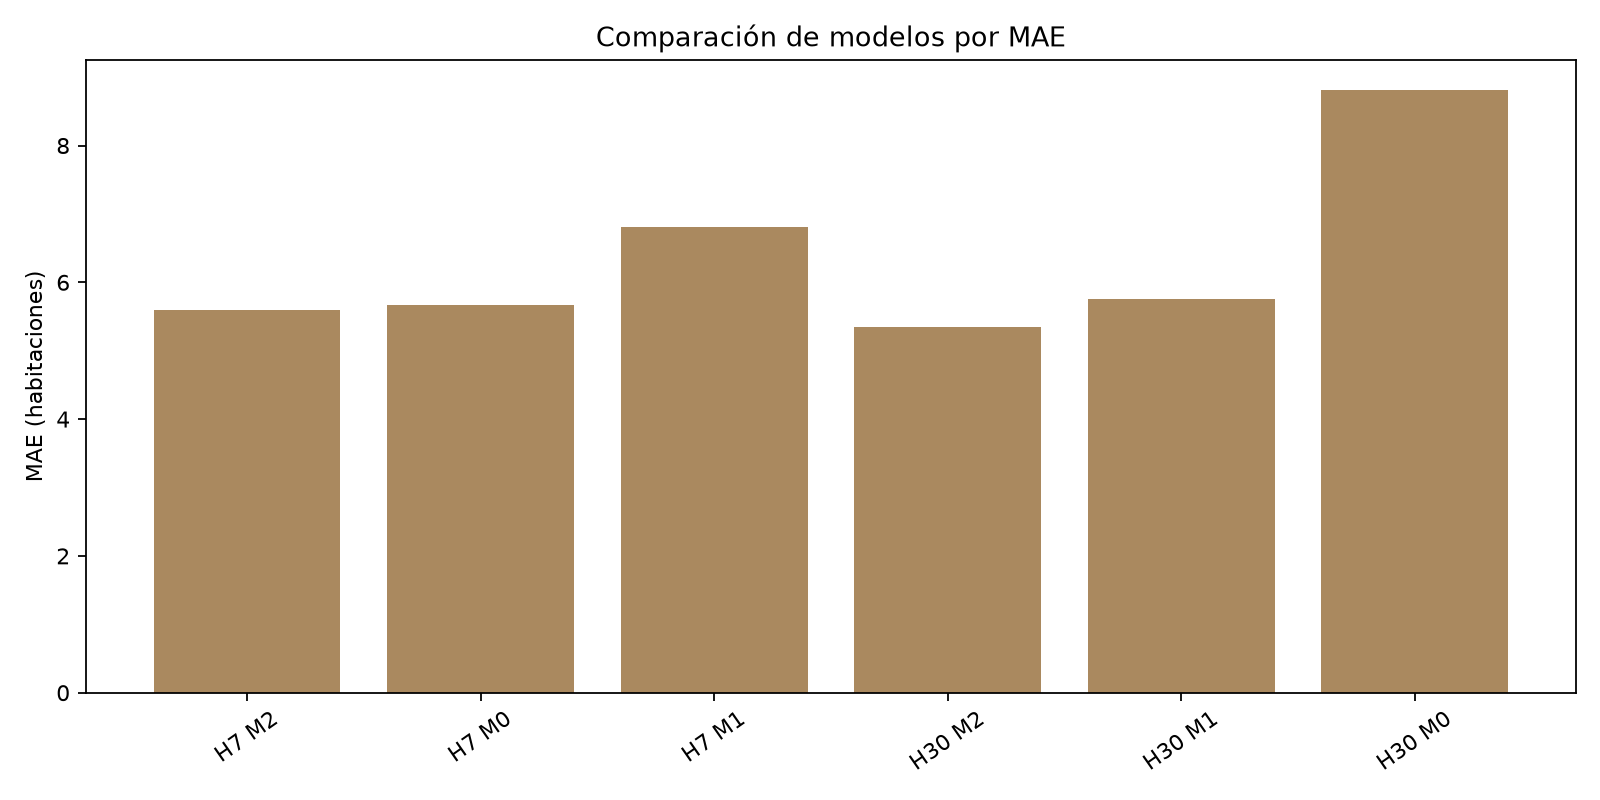

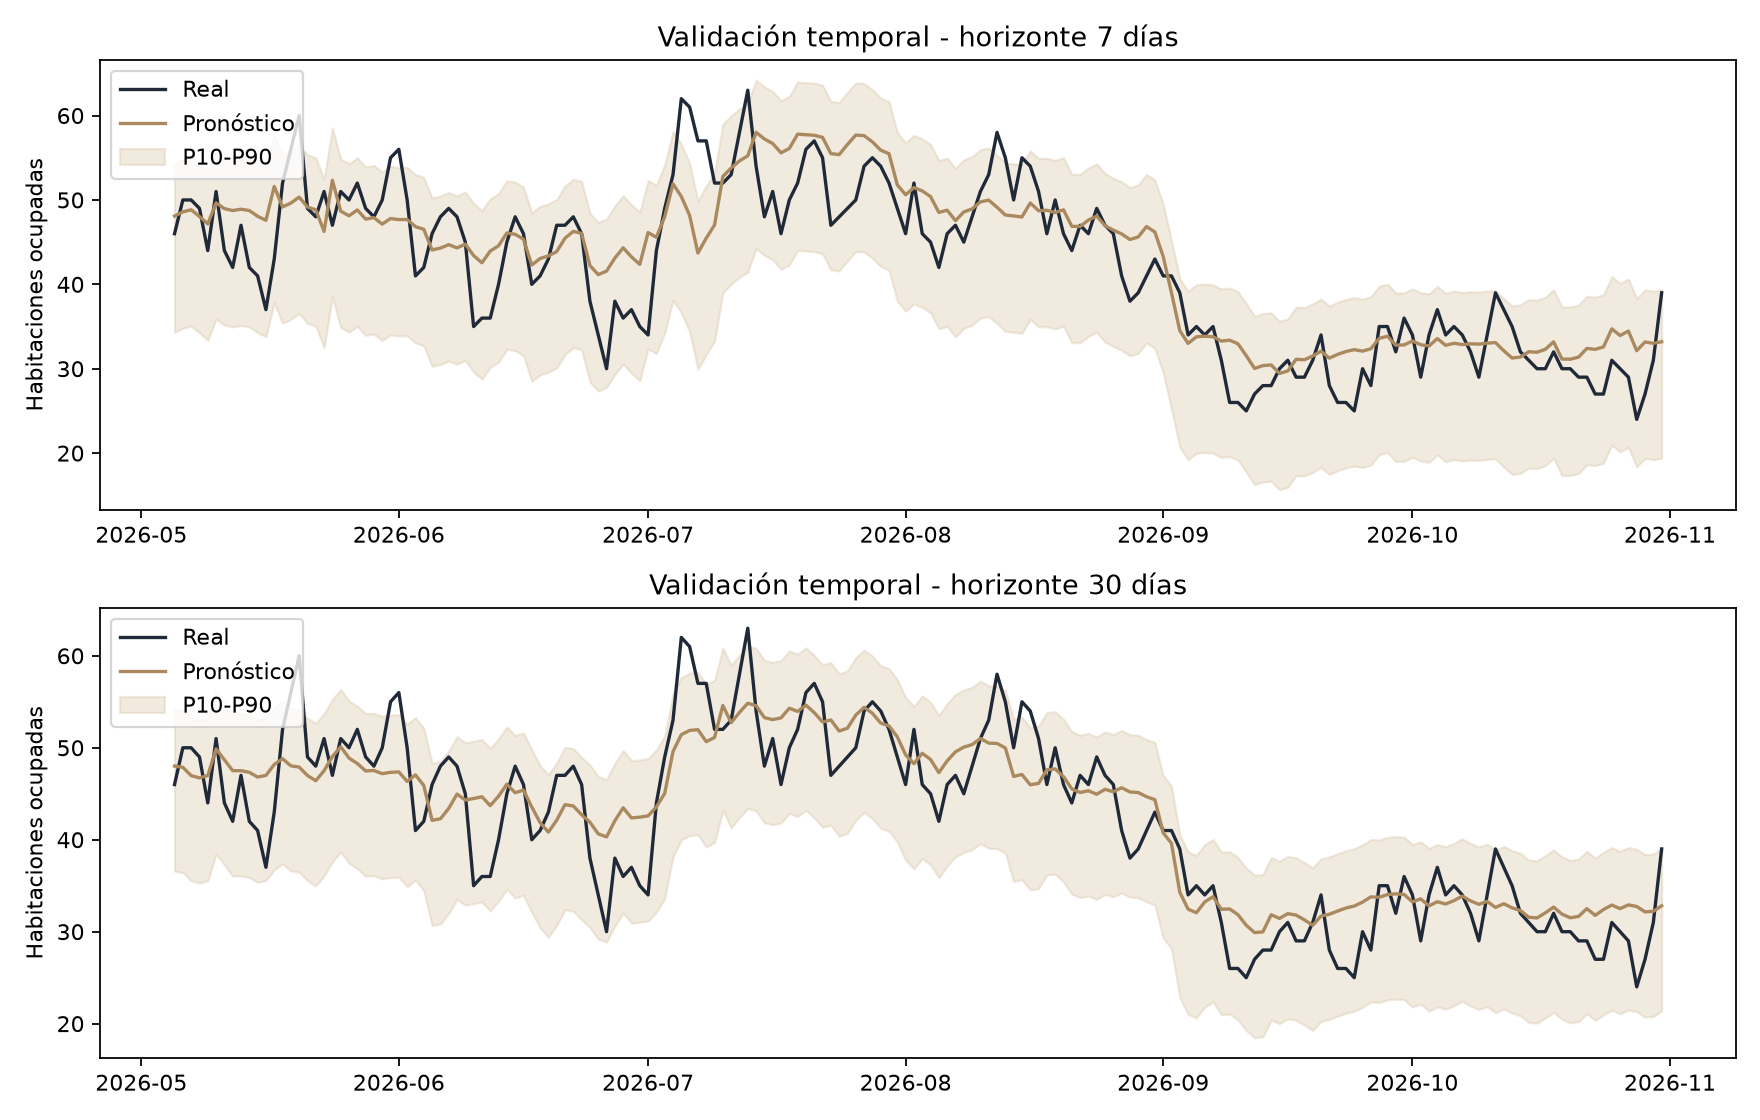

In [5]:
from IPython.display import Image, display
display(Image(filename=str(ML_DIR / 'reports' / 'model_comparison.png')))
display(Image(filename=str(ML_DIR / 'reports' / 'temporal_validation.png')))

## Conclusión y límites

Los artefactos seleccionados se guardan en `ml/models/` y las métricas en `ml/reports/`. Estos resultados son evidencia experimental, no una decisión operativa automática. La primera versión no ejecuta acciones sobre el PMS, no reentrena automáticamente y no debe interpretarse como pronóstico por sede. Para resultados productivos se debe repetir el experimento con datos reales obtenidos mediante `export_reservations.py`.